# House Price Prediction - Model Evaluation

This notebook loads the saved Linear Regression pipeline and evaluates it on the same held-out test split used during training. It does not fit or retrain the model, and it does not change the original CSV.

## 1. Load the original data and saved pipeline

The target is the verified `price` column. The pipeline file includes the fitted imputers, one-hot encoder, and Linear Regression model.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split

data_path = Path("../dataset/Housing.csv")
model_path = Path("../model/house_price_model.pkl")
houses_from_file = pd.read_csv(data_path)
model_pipeline = joblib.load(model_path)

print(f"Loaded dataset: {data_path.name}")
print("Dataset shape:", houses_from_file.shape)
print("Actual columns:", houses_from_file.columns.tolist())
print("Loaded pipeline steps:", list(model_pipeline.named_steps.keys()))

Loaded dataset: Housing.csv
Dataset shape: (545, 13)
Actual columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
Loaded pipeline steps: ['preprocessor', 'linear_regression']


## 2. Repeat the training notebook's preparation rules

To reproduce the same test records, apply the same duplicate, missing-target, category-normalization, and numeric-validity rules before splitting. These checks do not learn statistical values. The saved pipeline will apply the fitted imputers and encoder to the test features.

In [2]:
target_column = "price"
if target_column not in houses_from_file.columns:
    raise KeyError(f"Target column {target_column!r} was not found. Review the dataset columns.")

houses = houses_from_file.copy()
duplicate_rows_removed = int(houses.duplicated().sum())
houses = houses.drop_duplicates().copy()

missing_target_rows_removed = int(houses[target_column].isna().sum())
houses = houses.dropna(subset=[target_column]).copy()

categorical_columns = houses.select_dtypes(include=["object", "category", "string"]).columns.tolist()
for column in categorical_columns:
    houses[column] = houses[column].astype("string").str.strip().str.lower()

expected_categories = {
    "mainroad": {"yes", "no"},
    "guestroom": {"yes", "no"},
    "basement": {"yes", "no"},
    "hotwaterheating": {"yes", "no"},
    "airconditioning": {"yes", "no"},
    "prefarea": {"yes", "no"},
    "furnishingstatus": {"furnished", "semi-furnished", "unfurnished"},
}
unexpected_categories = {}
for column, allowed_values in expected_categories.items():
    if column in houses.columns:
        observed_values = set(houses[column].dropna().unique())
        unexpected_values = observed_values - allowed_values
        if unexpected_values:
            unexpected_categories[column] = sorted(unexpected_values)
if unexpected_categories:
    raise ValueError(f"Review unexpected categorical values before continuing: {unexpected_categories}")

positive_columns = [
    column for column in ["price", "area", "bedrooms", "bathrooms", "stories"]
    if column in houses.columns
]
invalid_numeric_rows = pd.Series(False, index=houses.index)
for column in positive_columns:
    invalid_numeric_rows |= houses[column].notna() & houses[column].le(0)
if "parking" in houses.columns:
    invalid_numeric_rows |= houses["parking"].notna() & houses["parking"].lt(0)

invalid_numeric_rows_removed = int(invalid_numeric_rows.sum())
houses = houses.loc[~invalid_numeric_rows].copy()

print("Duplicate rows removed:", duplicate_rows_removed)
print("Rows removed because price was missing:", missing_target_rows_removed)
print("Rows removed for invalid numeric values:", invalid_numeric_rows_removed)
print("Rows available for the same split:", len(houses))

Duplicate rows removed: 0
Rows removed because price was missing: 0
Rows removed for invalid numeric values: 0
Rows available for the same split: 545


## 3. Recreate the 80/20 train-test split

The same `test_size=0.2` and `random_state=42` are used as in model development, after applying the same deterministic preparation rules. The training portion is only used to reproduce the split; the saved model is not fitted again. Predictions and metrics below use `X_test` and `y_test` only.

In [3]:
X = houses.drop(columns=[target_column]).copy()
y = houses[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

assert set(X_train.index).isdisjoint(X_test.index)
assert list(model_pipeline.feature_names_in_) == list(X.columns)

print("Target column:", target_column)
print("Training records in reproduced split:", len(X_train))
print("Testing records:", len(X_test))
print("First 10 original row indices in the test split:", X_test.index[:10].tolist())
print("Feature columns match the saved pipeline:", list(X.columns) == list(model_pipeline.feature_names_in_))

Target column: price
Training records in reproduced split: 436
Testing records: 109
First 10 original row indices in the test split: [316, 77, 360, 90, 493, 209, 176, 249, 516, 426]
Feature columns match the saved pipeline: True


## 4. Predict on the test data only

`predict` uses the preprocessing steps already fitted and saved inside the pipeline. There is no call to `fit` in this evaluation notebook.

In [4]:
predicted_prices = model_pipeline.predict(X_test)
residuals = y_test.to_numpy() - predicted_prices

assert len(predicted_prices) == len(y_test)
assert np.isfinite(predicted_prices).all()
print(f"Generated predictions for {len(predicted_prices)} held-out test records.")

Generated predictions for 109 held-out test records.


## 5. Evaluation metrics

All metrics compare predictions for the held-out test set with its actual `price` values.

- **Mean Absolute Error (MAE):** the average absolute difference between predicted and actual price. It is in the dataset's price units; lower is better.
- **Mean Squared Error (MSE):** the average squared difference. It is in squared price units and penalizes large errors more strongly; lower is better.
- **Root Mean Squared Error (RMSE):** the square root of MSE. It returns to price units while still giving extra weight to larger errors; lower is better.
- **R² score:** the fraction of variation in test prices explained by the predictions relative to predicting the test-set mean. A score closer to 1 is better; 0 is equivalent to that mean baseline, and a negative score is worse.

In [5]:
mae = mean_absolute_error(y_test, predicted_prices)
mse = mean_squared_error(y_test, predicted_prices)
rmse = root_mean_squared_error(y_test, predicted_prices)
r2 = r2_score(y_test, predicted_prices)

metrics_table = pd.DataFrame(
    {
        "Metric": ["MAE", "MSE", "RMSE", "R² score"],
        "Value": [mae, mse, rmse, r2],
    }
)
metrics_table["Value"] = [f"{mae:,.2f}", f"{mse:,.2f}", f"{rmse:,.2f}", f"{r2:.4f}"]
display(metrics_table)

mae_as_percent_of_mean_price = mae / y_test.mean() * 100
print(f"Mean test price: {y_test.mean():,.2f}")
print(f"MAE as a share of the mean test price: {mae_as_percent_of_mean_price:.1f}%")

,Metric,Value
0,MAE,"970,043.40"
1,MSE,"1,754,318,687,330.66"
2,RMSE,"1,324,506.96"
3,R² score,0.6529


Mean test price: 5,007,536.70
MAE as a share of the mean test price: 19.4%


## 6. Interpret the calculated results

Use the printed values rather than a universal pass/fail cutoff: R² describes how much test-price variation the model explains, while MAE gives the typical absolute error in price units. Comparing MAE with the mean test price gives context for the size of that error. RMSE being noticeably higher than MAE suggests larger errors are affecting the result more.

In [6]:
if r2 >= 0:
    print(f"R² interpretation: the predictions explain about {r2 * 100:.1f}% of the variation in held-out house prices.")
else:
    print(f"R² interpretation: {r2:.3f} is below zero, so the predictions are worse than using the test-set mean as a baseline.")

print(
    f"Error interpretation: the average absolute error is {mae:,.0f} price units, "
    f"or {mae_as_percent_of_mean_price:.1f}% of the mean test price."
)
if rmse > mae:
    print(f"RMSE ({rmse:,.0f}) exceeds MAE ({mae:,.0f}), indicating that larger residuals increase the squared-error penalty.")
print("This is an initial model baseline; decide whether its error is acceptable for the intended use before relying on individual predictions.")

R² interpretation: the predictions explain about 65.3% of the variation in held-out house prices.
Error interpretation: the average absolute error is 970,043 price units, or 19.4% of the mean test price.
RMSE (1,324,507) exceeds MAE (970,043), indicating that larger residuals increase the squared-error penalty.
This is an initial model baseline; decide whether its error is acceptable for the intended use before relying on individual predictions.


## 7. Actual vs. predicted prices

Each point is a test record. The dashed line marks perfect predictions; points nearer the line have smaller errors. The figure is saved for later reference.

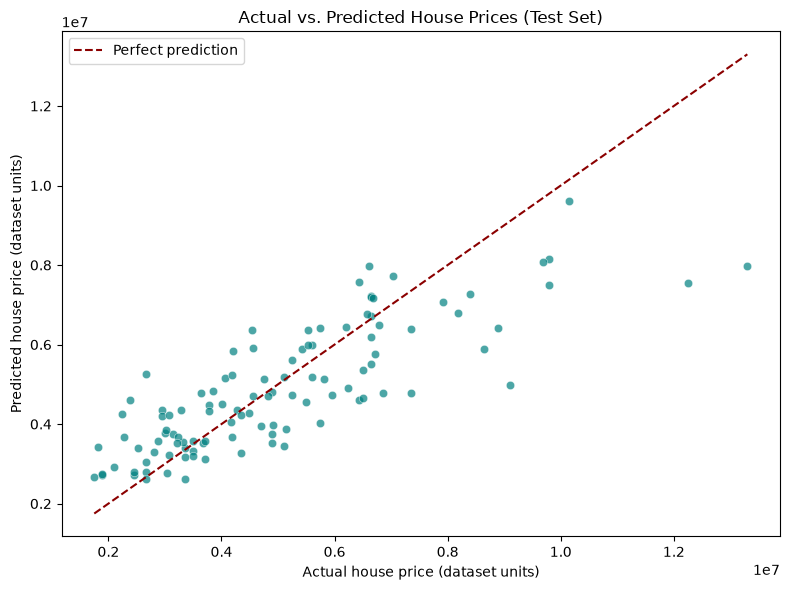

Saved: ..\outputs\visualizations\evaluation_actual_vs_predicted_prices.png


In [7]:
visualization_dir = Path("../outputs/visualizations")
visualization_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, predicted_prices, alpha=0.7, color="teal", edgecolor="white", linewidth=0.4)
plot_min = min(float(y_test.min()), float(predicted_prices.min()))
plot_max = max(float(y_test.max()), float(predicted_prices.max()))
ax.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--", color="darkred", label="Perfect prediction")
ax.set_title("Actual vs. Predicted House Prices (Test Set)")
ax.set_xlabel("Actual house price (dataset units)")
ax.set_ylabel("Predicted house price (dataset units)")
ax.legend()
fig.tight_layout()

actual_predicted_plot_path = visualization_dir / "evaluation_actual_vs_predicted_prices.png"
fig.savefig(actual_predicted_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", actual_predicted_plot_path)

## 8. Residual distribution

A residual is the actual price minus the predicted price. Values near zero are small errors; positive values mean the model predicted too low, and negative values mean it predicted too high. This histogram shows the spread and shape of test residuals.

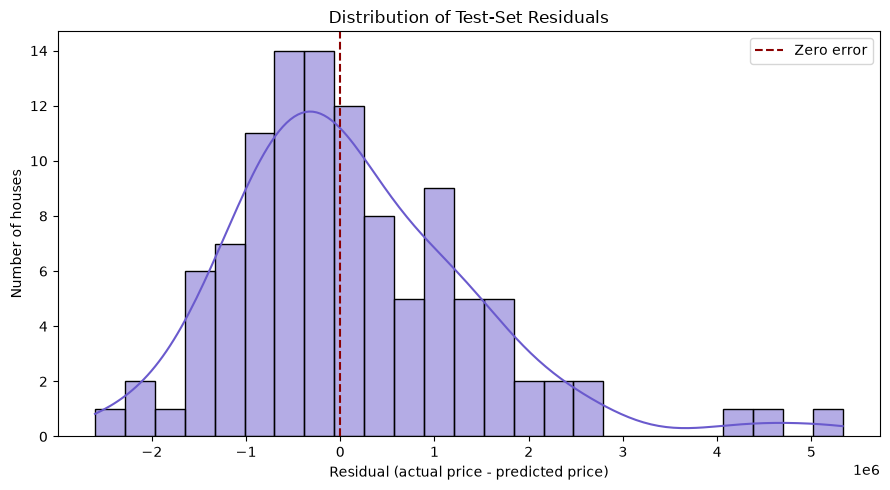

Saved: ..\outputs\visualizations\evaluation_residual_distribution.png


In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(residuals, bins=25, kde=True, color="slateblue", ax=ax)
ax.axvline(0, color="darkred", linestyle="--", label="Zero error")
ax.set_title("Distribution of Test-Set Residuals")
ax.set_xlabel("Residual (actual price - predicted price)")
ax.set_ylabel("Number of houses")
ax.legend()
fig.tight_layout()

residual_histogram_path = visualization_dir / "evaluation_residual_distribution.png"
fig.savefig(residual_histogram_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", residual_histogram_path)

## 9. Residuals vs. predicted prices

This scatter plot checks whether errors are centered around zero across the prediction range. A visible curve or changing spread can indicate patterns the linear model does not capture.

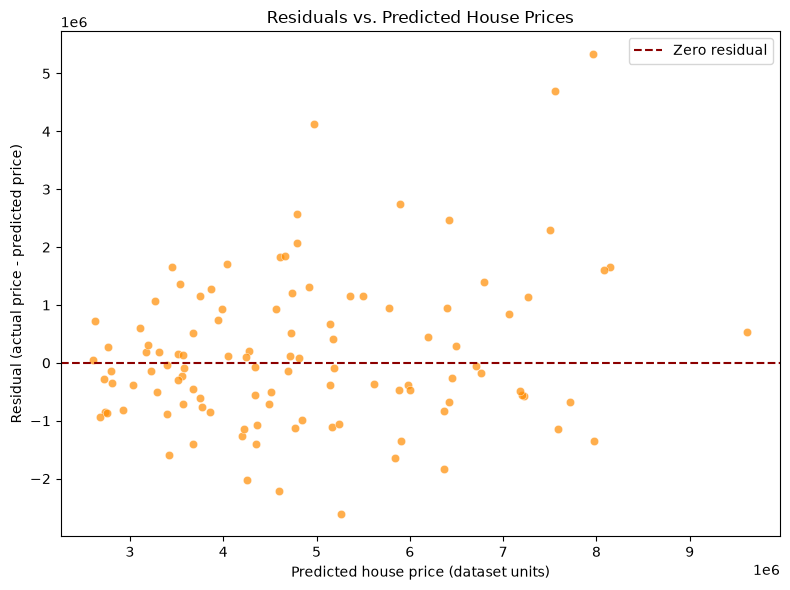

Saved: ..\outputs\visualizations\evaluation_residuals_vs_predicted_prices.png


In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(predicted_prices, residuals, alpha=0.7, color="darkorange", edgecolor="white", linewidth=0.4)
ax.axhline(0, color="darkred", linestyle="--", label="Zero residual")
ax.set_title("Residuals vs. Predicted House Prices")
ax.set_xlabel("Predicted house price (dataset units)")
ax.set_ylabel("Residual (actual price - predicted price)")
ax.legend()
fig.tight_layout()

residual_scatter_path = visualization_dir / "evaluation_residuals_vs_predicted_prices.png"
fig.savefig(residual_scatter_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", residual_scatter_path)

## Evaluation complete

The four scores and three diagnostic charts are based on the saved model's predictions for the reproduced test set. No model fitting or changes to the original dataset were performed.

In [10]:
evaluation_plot_paths = [
    actual_predicted_plot_path,
    residual_histogram_path,
    residual_scatter_path,
]
assert all(path.exists() and path.stat().st_size > 0 for path in evaluation_plot_paths)
for path in evaluation_plot_paths:
    print(f"{path.name}: {path.stat().st_size:,} bytes")
print("All evaluation charts were saved successfully.")

evaluation_actual_vs_predicted_prices.png: 71,619 bytes
evaluation_residual_distribution.png: 56,208 bytes
evaluation_residuals_vs_predicted_prices.png: 49,576 bytes
All evaluation charts were saved successfully.
